[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/08_pca_plotting.py)

# High-Dimensional GMM Visualization with PCA

`plot_gmm` draws two-dimensional data, but real mixtures often live in many more dimensions. This notebook shows a workflow for visualizing them: fit the `GaussianMixture` on the original high-dimensional data, reduce the data (and any samples) to 2-D with PCA for display, and read the plot together with the PCA explained-variance ratios.

**What you'll learn**

- Fit a GMM in 10 dimensions and visualize it in a 2-D PCA projection
- Project samples from the high-dimensional model (core and tail regions) into the same plane
- Why "projecting a fitted model" and "fitting a model to projected data" are different things

**Prerequisites:** [03 -- Visualization](03_visualise.ipynb).

**See also:** the [Plotting & Visualization user guide](../user-guide/plotting.md).

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler


from tgmm import GaussianMixture, plot_gmm, dynamic_figsize, gmm_proxy

plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; keep embedded figure outputs small

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Example: High-Dimensional Synthetic Data

Let's start with synthetic high-dimensional data to demonstrate the PCA functionality.

In [ ]:
# Generate high-dimensional synthetic data
n_samples = 1000
n_features = 10
n_centers = 4

# Create high-dimensional clusters
X_high_dim, true_labels = make_blobs(
    n_samples=n_samples,
    centers=n_centers,
    n_features=n_features,
    cluster_std=2.0,
    random_state=SEED
)

# Standardize the data
scaler = StandardScaler()
X_high_dim = scaler.fit_transform(X_high_dim)

print(f"Original data shape: {X_high_dim.shape}")
print(f"Number of clusters: {n_centers}")
print(f"Features range: [{X_high_dim.min():.2f}, {X_high_dim.max():.2f}]")

Original data shape: (1000, 10)
Number of clusters: 4
Features range: [-2.99, 3.03]


In [ ]:
# Convert to tensor
X_tensor = torch.tensor(X_high_dim, dtype=torch.float32, device=device)

# Fit GMM on the high-dimensional data
gmm_high_dim = GaussianMixture(
    n_components=n_centers,
    covariance_type='full',
    max_iter=2 * MAX_ITER,
    random_state=SEED,
    device=device
)

# Fit the model
gmm_high_dim.fit(X_tensor)

# Get predictions
predicted_labels = gmm_high_dim.predict(X_tensor).cpu().numpy()
log_probs = gmm_high_dim.score_samples(X_tensor).cpu().numpy()

# Sample from the core region (inside the 95% confidence region)
sample_core, _ = gmm_high_dim.sample(n_samples=500, confidence_range=(0, 0.95))
sample_core = sample_core.cpu().numpy()

# Sample from the tails (outside the 95% confidence region)
sample_tails, _ = gmm_high_dim.sample(n_samples=500, confidence_range=(0.95, 0.9999999999999))
sample_tails = sample_tails.cpu().numpy()

In [ ]:
# Apply PCA to reduce dimensionality for visualization
from sklearn.decomposition import PCA

# Fit PCA on the high-dimensional data
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_high_dim)

# Transform sampled data to PCA space
sample_core_pca = pca.transform(sample_core)
sample_tails_pca = pca.transform(sample_tails)

# Create a simplified 2D GMM for visualization purposes
# (This is just for plotting - the original high-D GMM is still the "true" model)
X_pca_tensor = torch.tensor(X_pca, dtype=torch.float32, device=device)

# Fit a 2D GMM on the PCA-transformed data for visualization
gmm_2d = GaussianMixture(
    n_components=n_centers,
    covariance_type='full',
    max_iter=MAX_ITER,
    random_state=SEED,
    device=device
)
gmm_2d.fit(X_pca_tensor)

# Get predictions from the 2D GMM
predicted_labels_2d = gmm_2d.predict(X_pca_tensor).cpu().numpy()

print(f"PCA explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.3f}")
print(f"PC1 explains {pca.explained_variance_ratio_[0]:.1%} of variance")
print(f"PC2 explains {pca.explained_variance_ratio_[1]:.1%} of variance")

PCA explained variance ratio: [0.55261046 0.1964909 ]
Total explained variance: 0.749
PC1 explains 55.3% of variance
PC2 explains 19.6% of variance


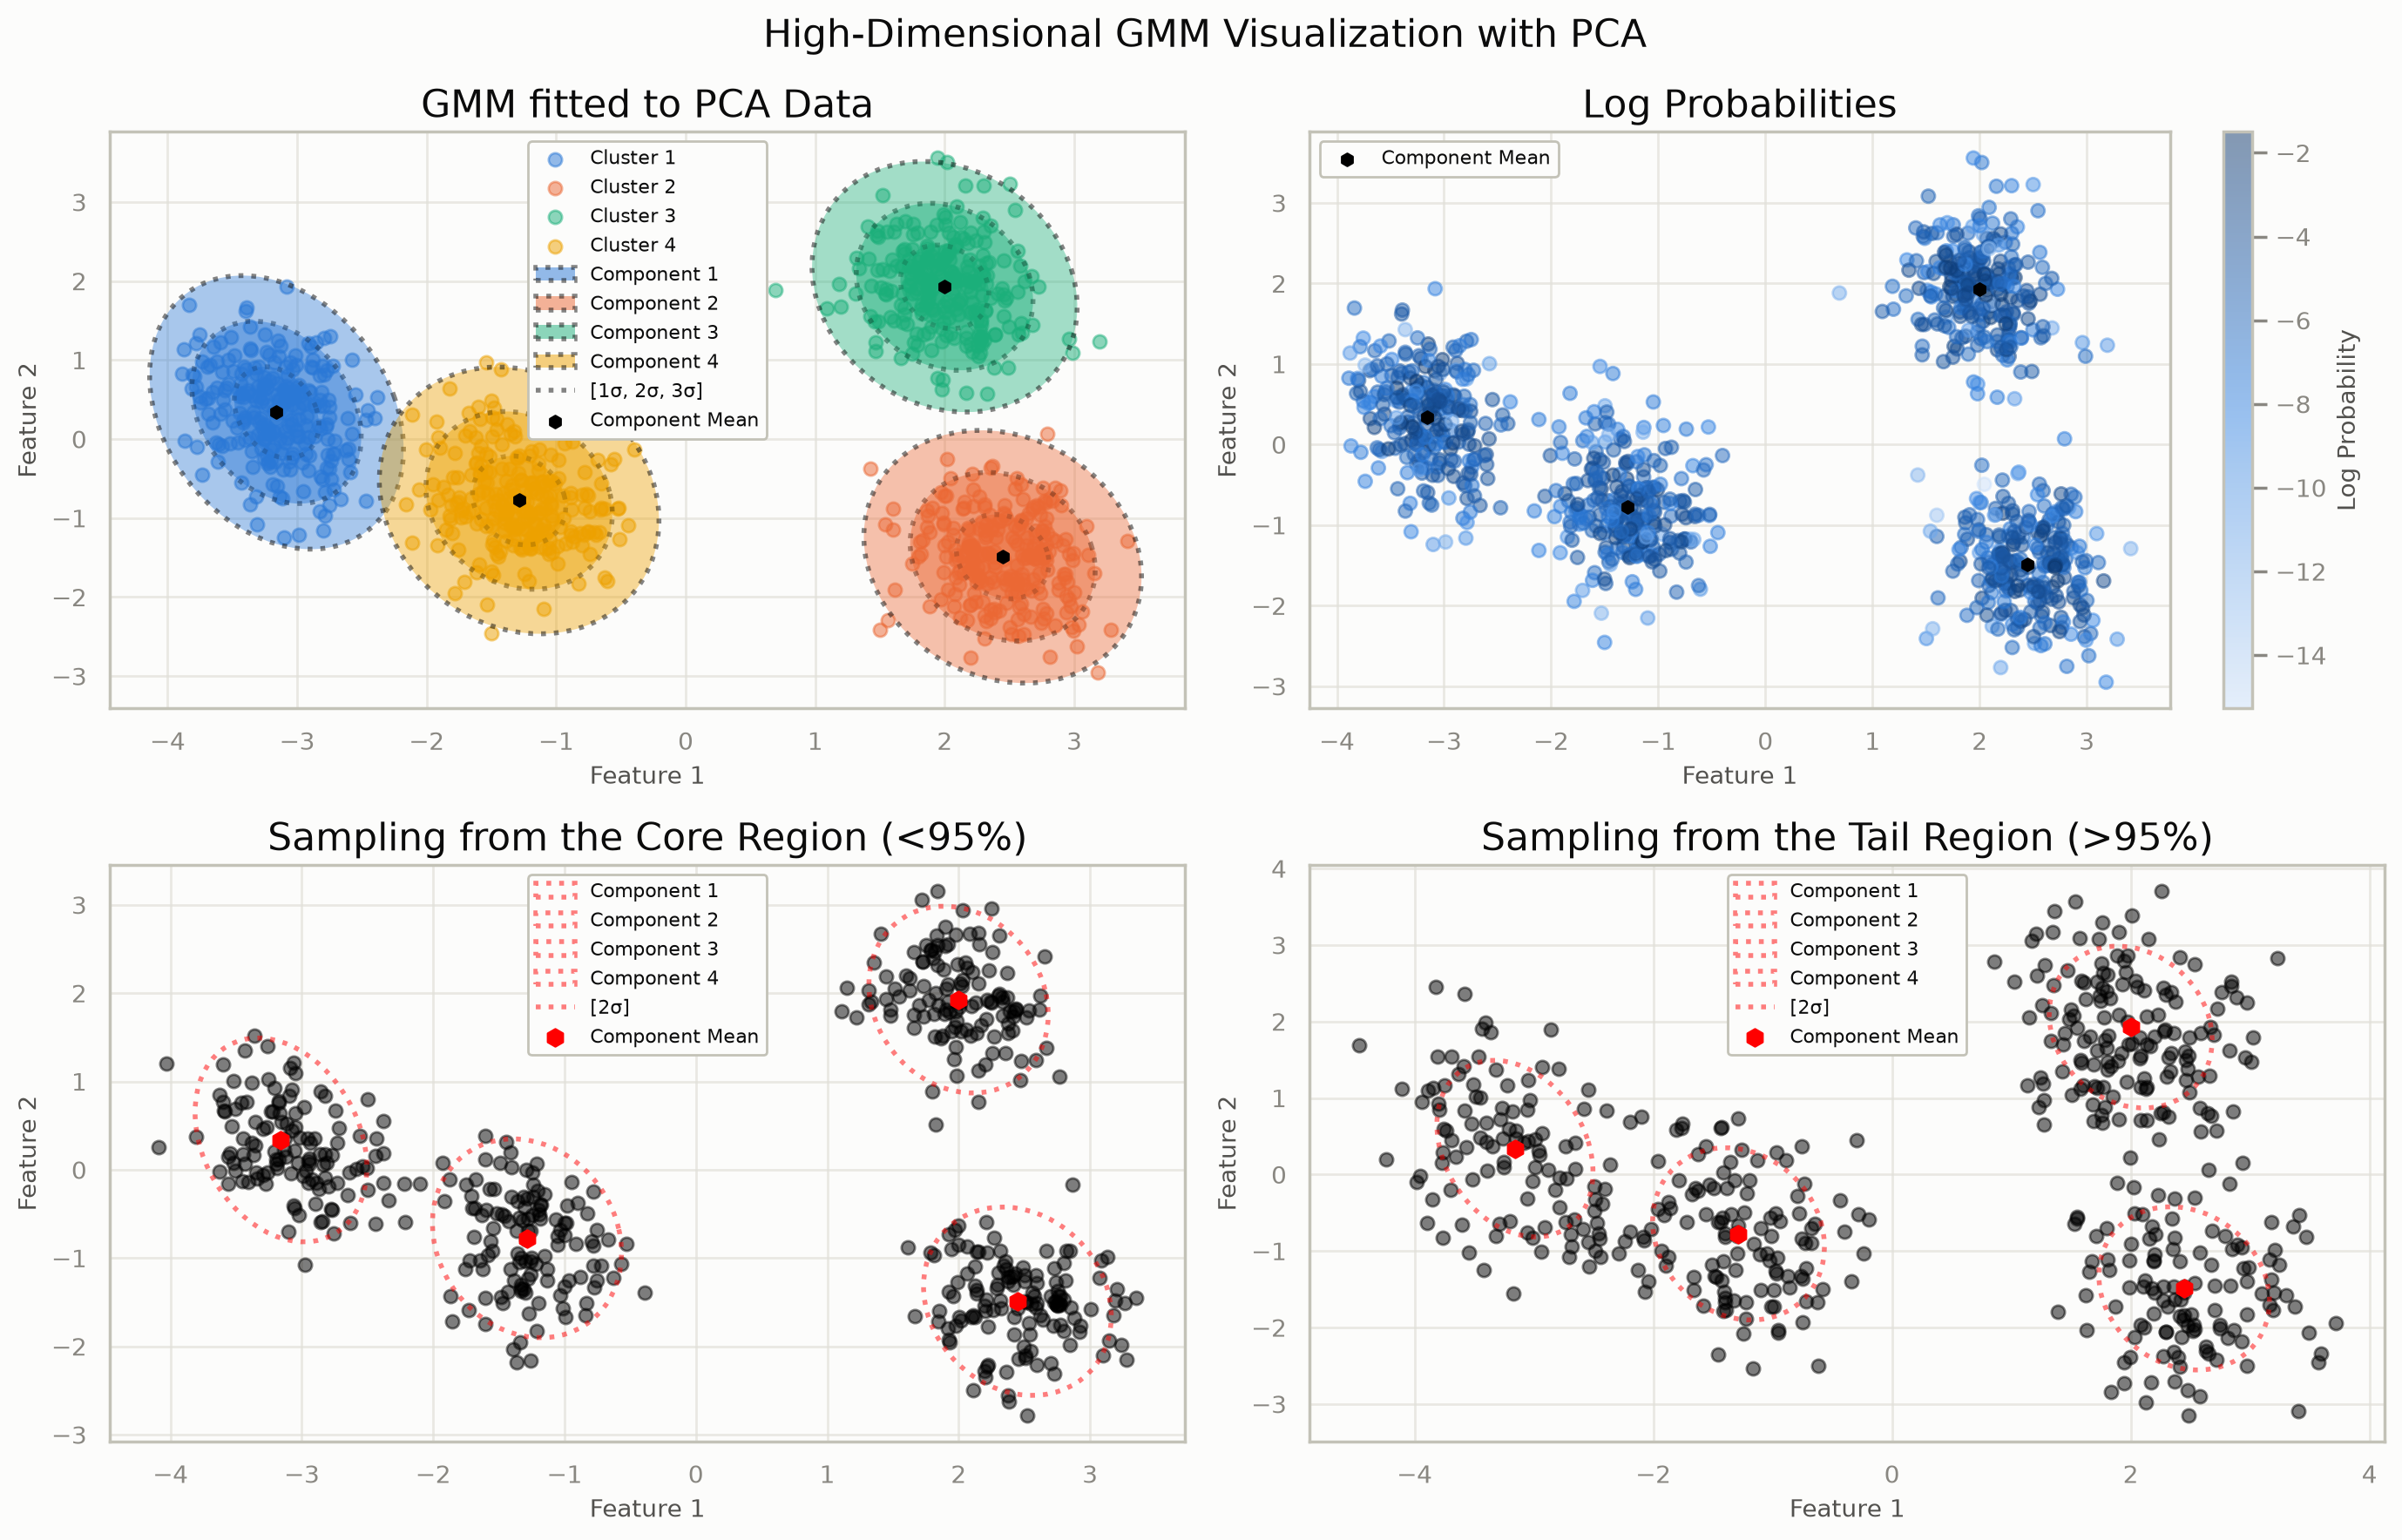

In [ ]:
nrows, ncols = (2, 2)
figsize = dynamic_figsize(nrows, ncols)
_fig, _axes = plt.subplots(nrows, ncols, figsize=figsize)
_axes = _axes.flatten()
_fig.suptitle('High-Dimensional GMM Visualization with PCA', fontsize=16)
plot_gmm(X_pca, gmm=gmm_2d, color_by_cluster=True, title='GMM fitted to PCA Data', ax=_axes[0], point_size=30)
# 1. The 2-D GMM fitted to the PCA data, colored by cluster
plot_gmm(X_pca, gmm=gmm_2d, log_probs=log_probs, title='Log Probabilities', ax=_axes[1], show_ellipses=False, point_size=30)
plot_gmm(sample_core_pca, gmm=gmm_2d, title='Sampling from the Core Region (<95%)', ax=_axes[2], show_ellipses=True, ellipse_std_devs=[2], ellipse_line_color='red', ellipse_fill=False, point_size=30, mean_color='red', mean_size=50)
plot_gmm(sample_tails_pca, gmm=gmm_2d, title='Sampling from the Tail Region (>95%)', ax=_axes[3], show_ellipses=True, ellipse_std_devs=[2], ellipse_line_color='red', ellipse_fill=False, point_size=30, mean_color='red', mean_size=50)
plt.tight_layout()
# 2. Continuous coloring with the high-dimensional model's log probabilities
# 3. Samples from the high-dimensional model's core region, projected with the same PCA
# 4. Tail samples from the high-dimensional model, projected with the same PCA
plt.gcf()

### Projecting a fitted GMM vs. fitting a GMM to projected data

"A GMM in PCA space" can mean two different things, and they are not the same model.

**(a) Project the high-dimensional model.** If $x \sim \sum_k \pi_k \mathcal{N}(\mu_k, \Sigma_k)$ and $y = A(x - m)$ with $A \in \mathbb{R}^{2\times d}$ (the PCA components, $m$ the data mean), then

$$
y \sim \sum_{k=1}^K \pi_k \, \mathcal{N}\big(y;\, A(\mu_k - m),\, A\Sigma_k A^\top\big).
$$

This is exact: a linear map sends each Gaussian component to a Gaussian, and the mixture weights are unchanged. It is the faithful two-dimensional picture of the model fitted in $d$ dimensions.

**(b) Fit a new GMM to the projected points.** Maximum likelihood is *equivariant* under invertible linear maps: for a square, full-rank $A$, the log-likelihood of $\{Ax_i\}$ equals that of $\{x_i\}$ minus the constant $n\log|\det A|$, so the maximizer of one is the image of the maximizer of the other. A 2-D PCA projection is **not** invertible. It discards $d-2$ directions, the likelihood of the projected data is a different function of the parameters, and the 2-D maximum-likelihood fit generally differs from (a) -- for example, components separated only along discarded directions overlap in the projection, and the 2-D fit may merge or reshuffle them.

The panels above use (b) (`gmm_2d`) for the ellipses because it is a proper model of what you see in the plane. The next cell draws (a) for comparison, using the high-dimensional fit's own clusters for the colors.

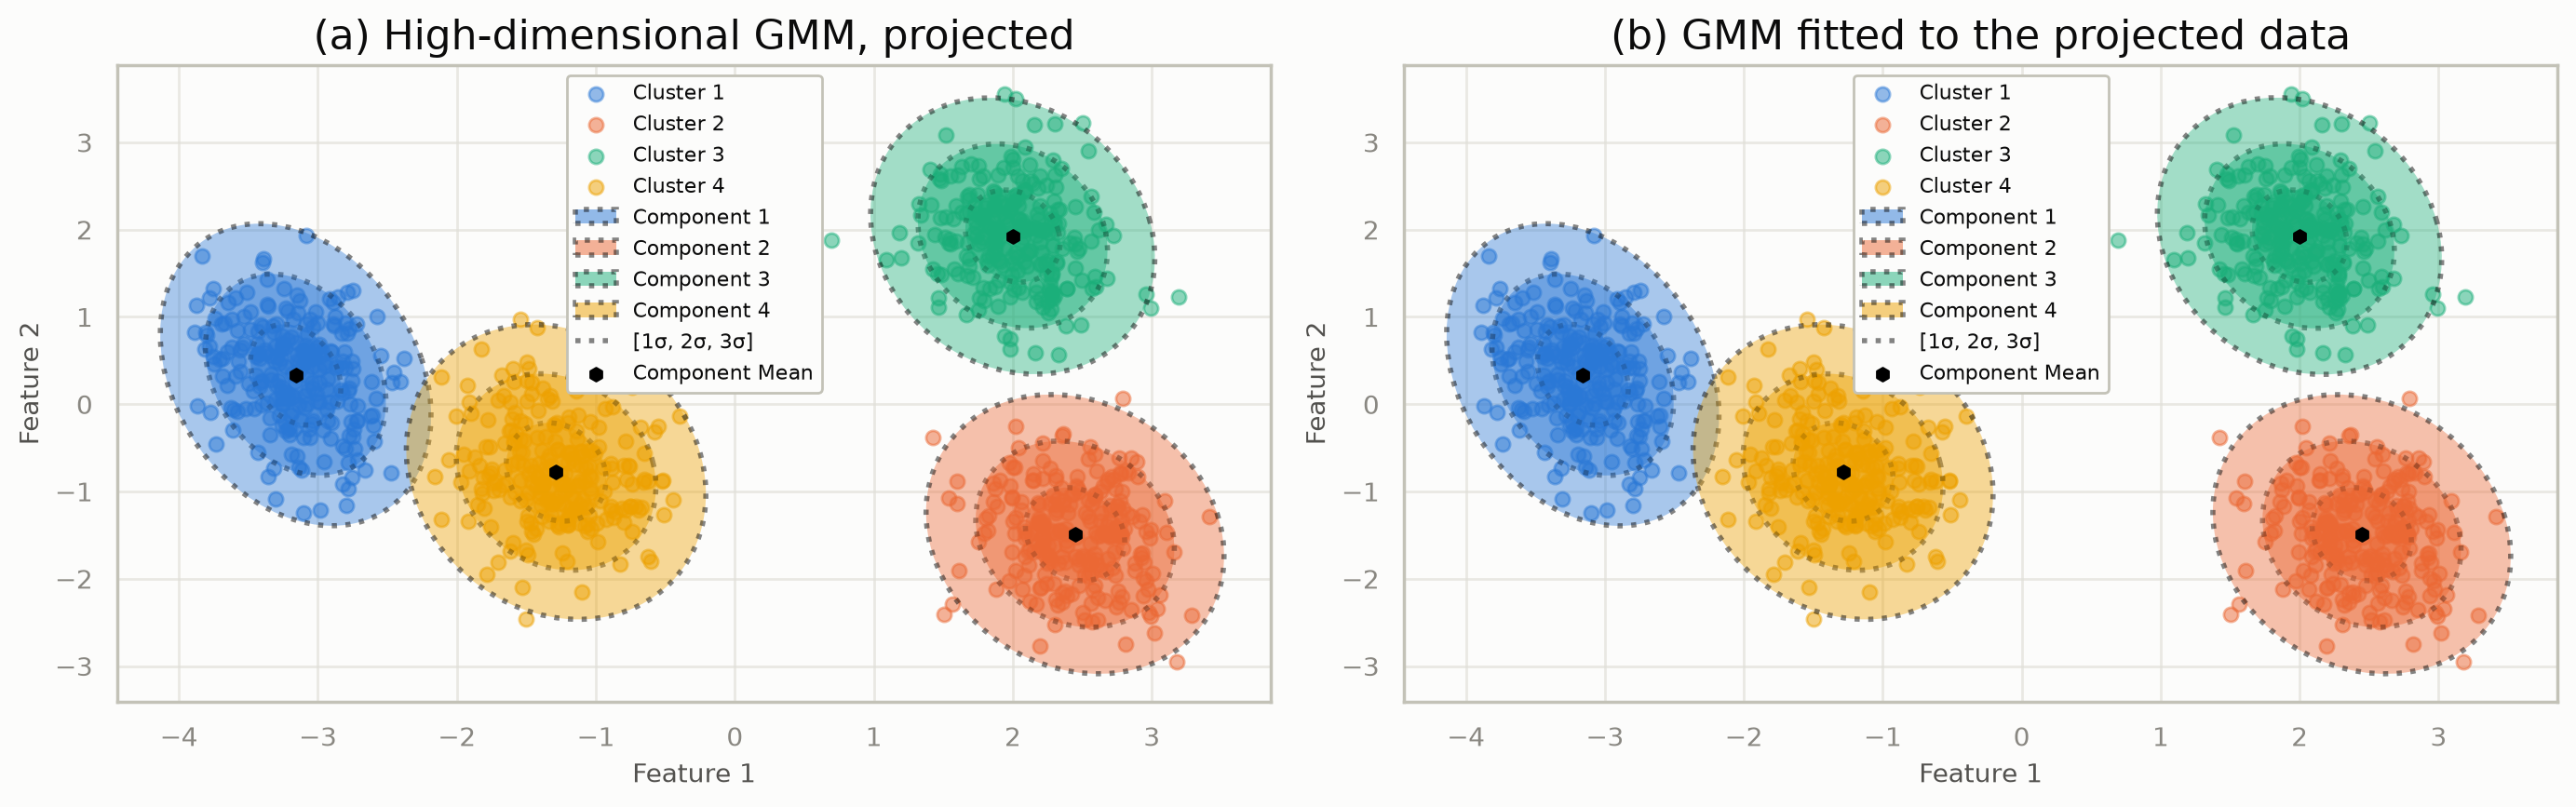

In [ ]:
# (a) Project the high-dimensional model: means -> A(mu_k - m), covariances -> A Sigma_k A^T
A = pca.components_  # (2, d)
means_hd = gmm_high_dim.means_.cpu().numpy()  # (K, d)
covs_hd = gmm_high_dim.covariances_.cpu().numpy()  # (K, d, d)
means_proj = pca.transform(means_hd)  # A (mu_k - m)
covs_proj = np.einsum('ij,kjl,ml->kim', A, covs_hd, A)  # A Sigma_k A^T
proj_proxy = gmm_proxy(means=means_proj, covariances=covs_proj, weights=gmm_high_dim.weights_.cpu().numpy(), covariance_type='full', predicted_labels=predicted_labels)
_fig, _axes = plt.subplots(1, 2, figsize=dynamic_figsize(1, 2))
plot_gmm(X_pca, gmm=proj_proxy, color_by_cluster=True, ax=_axes[0], point_size=30, title='(a) High-dimensional GMM, projected')
plot_gmm(X_pca, gmm=gmm_2d, color_by_cluster=True, ax=_axes[1], point_size=30, title='(b) GMM fitted to the projected data')
plt.tight_layout()
plt.gcf()

## Summary

- Fit the mixture on the original features -- that is where the structure is -- and use PCA only to draw it.
- Check `explained_variance_ratio_`: a projection that keeps little variance can hide cluster separation or make clusters appear to overlap.
- Samples from the high-dimensional model (e.g. via `confidence_range`) can be pushed through the same PCA to compare core and tail regions in the plane.
- A linear projection of a GMM is again a GMM with parameters $(\pi_k, A\mu_k, A\Sigma_k A^\top)$; this differs from refitting a GMM to the projected points, which is only equivalent for invertible maps.

**Next:** [09 -- Priors](09_priors.ipynb) for regularizing mixture fits, or [07 -- Sampling](07_sampling.ipynb) for the sampling options used here.